# 01 · The Precision You Don't Need

**Quantization 101** — *you can throw away three quarters of every number and barely notice.*

A 32-bit float carries about seven decimal digits of precision. A neural network's
weights — and the behavior they produce — depend on far less than that. This notebook
establishes the motivating fact before we learn *how* to exploit it: a real weight
matrix is smooth and bounded, occupies a limited range, and barely changes when we
round it onto a grid of just 256 (int8) or even 16 (int4) levels.

Connects to `information_theory_101`: how few bits actually carry the information.

In [1]:
import sys
from pathlib import Path

_root = Path.cwd()
if not (_root / "src").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import json
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

from src.artifacts import save_figure, save_json
from src.config import load_settings

settings = load_settings()
np.random.seed(settings.seed)
print("settings:", settings.model_dump())

settings: {'seed': 0, 'bit_widths': [8, 4], 'granularity': 'per_channel', 'channel_axis': 1, 'scheme': 'absmax', 'clip_percentile': 99.9, 'clip_sigma': 6.0, 'outlier_sigma': 6.0, 'model_name': 'distilgpt2', 'synthetic': {'rows': 256, 'cols': 256, 'outlier_scale': 10.0, 'n_outliers': 1}}


## A real weight matrix

We load a genuine matrix from `distilgpt2` so the distribution — including its
authentic heavy tails — is real, not synthetic.

In [2]:
from src.models.weights import load_model_weights

weights = load_model_weights(settings.model_name)
layer = next(k for k in weights if k.endswith("mlp.c_fc.weight"))
w = weights[layer]

facts = {
    "layer": layer,
    "shape": list(w.shape),
    "n_elements": int(w.size),
    "n_unique_fp32_values": int(np.unique(w).size),
    "fp32_bits_per_value": 32,
    "fp32_decimal_digits": 7,
    "min": float(w.min()),
    "max": float(w.max()),
    "std": float(w.std()),
    "absmax": float(np.abs(w).max()),
    "absmax_over_std": float(np.abs(w).max() / w.std()),
    "int8_levels": 256,
    "int4_levels": 16,
}
for k, v in facts.items():
    print(f"{k:>22}: {v}")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

                 layer: h.0.mlp.c_fc.weight
                 shape: [768, 3072]
            n_elements: 2359296
  n_unique_fp32_values: 2327217
   fp32_bits_per_value: 32
   fp32_decimal_digits: 7
                   min: -2.3516039848327637
                   max: 5.254800796508789
                   std: 0.14128759503364563
                absmax: 5.254800796508789
       absmax_over_std: 37.192230224609375
           int8_levels: 256
           int4_levels: 16


The matrix holds hundreds of thousands of values spread over a narrow range around
zero. That is exactly the shape that quantizes well: smooth, bounded, concentrated.

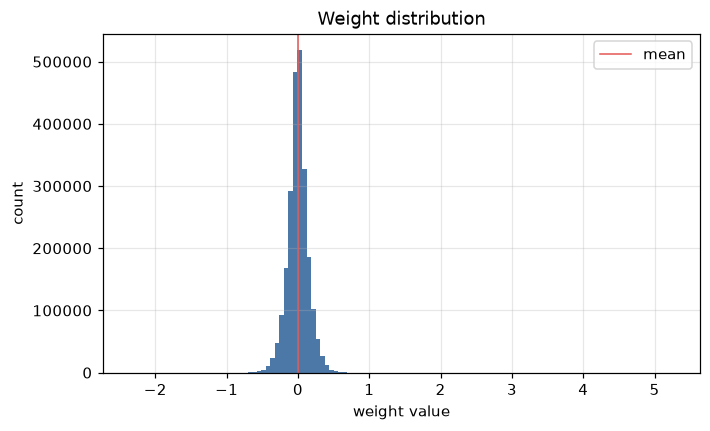

In [3]:
from src.visualisation import plot_weight_distribution

fig, ax = plt.subplots(figsize=(7, 4))
plot_weight_distribution(w, ax=ax)
ax.axvline(w.mean(), color="#E45756", lw=1, label="mean")
ax.legend()
save_figure(fig, "01_weight_distribution")
plt.show()

## Rounding to 256 levels barely moves anything

Now reduce the precision: map the weights onto an int8 grid (256 buckets) and an int4
grid (16 buckets), then reconstruct. The int8 histogram sits almost exactly on top of
the original — the relative error is about a percent. int4 is far coarser, and on *this*
matrix (whose largest weight is ~37× the typical size) it already shows strain: a first
hint of the outlier problem we dissect in notebook 03.

In [4]:
from src.evaluation.reconstruction import reconstruction_error
from src.quant.dequant import dequantize
from src.quant.granularity import quantize

qa8 = quantize(w, bits=8, scheme="absmax", granularity="per_channel", axis=1)
qa4 = quantize(w, bits=4, scheme="absmax", granularity="per_channel", axis=1)
w8, w4 = dequantize(qa8), dequantize(qa4)

err8 = reconstruction_error(w, w8)
err4 = reconstruction_error(w, w4)
facts["int8_rel_error"] = err8["rel_fro"]
facts["int4_rel_error"] = err4["rel_fro"]
facts["int8_snr_db"] = err8["snr_db"]
facts["int4_snr_db"] = err4["snr_db"]

print(f"int8 relative (Frobenius) error: {err8['rel_fro']:.4%}   SNR {err8['snr_db']:.1f} dB")
print(f"int4 relative (Frobenius) error: {err4['rel_fro']:.4%}   SNR {err4['snr_db']:.1f} dB")

int8 relative (Frobenius) error: 1.3392%   SNR 37.5 dB
int4 relative (Frobenius) error: 21.9418%   SNR 13.2 dB


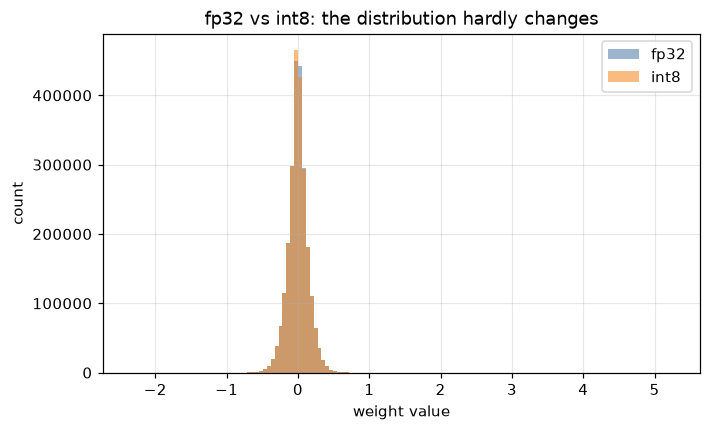

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(w.min(), w.max(), 140)
ax.hist(w.ravel(), bins=bins, alpha=0.55, label="fp32", color="#4C78A8")
ax.hist(w8.ravel(), bins=bins, alpha=0.55, label="int8", color="#F58518")
ax.set_xlabel("weight value")
ax.set_ylabel("count")
ax.set_title("fp32 vs int8: the distribution hardly changes")
ax.legend()
save_figure(fig, "01_fp32_vs_int8")
plt.show()

## Takeaway

The weights never used most of their 32 bits. At int8 the reconstruction error is tiny
(~1%), because the aggregate behavior of many weights is robust to small per-weight
rounding. int4 is coarser and this heavy-tailed matrix already strains it — the exact
tension the rest of the series resolves. Precision is **reducible**. Next: build the
operation that reduces it, and measure exactly what it costs.

In [6]:
path = save_json(facts, "01_results")
print("saved", path)
facts

saved /workspaces/quantization_101/outputs/data/01_results.json


{'layer': 'h.0.mlp.c_fc.weight',
 'shape': [768, 3072],
 'n_elements': 2359296,
 'n_unique_fp32_values': 2327217,
 'fp32_bits_per_value': 32,
 'fp32_decimal_digits': 7,
 'min': -2.3516039848327637,
 'max': 5.254800796508789,
 'std': 0.14128759503364563,
 'absmax': 5.254800796508789,
 'absmax_over_std': 37.192230224609375,
 'int8_levels': 256,
 'int4_levels': 16,
 'int8_rel_error': 0.013391613028943539,
 'int4_rel_error': 0.21941764652729034,
 'int8_snr_db': 37.463351607731745,
 'int4_snr_db': 13.17457475824167}